In [1]:
from pathlib import Path
Path("../src/__init__.py").write_text("")

0

In [2]:
%%writefile ../src/rates.py
import numpy as np


def simulate_vasicek(r0, a, b, sigma, T, n_steps, n_paths, seed=None):
    """Simula trayectorias de la tasa corta con el modelo de Vasicek."""
    rng = np.random.default_rng(seed)
    dt = T / n_steps

    rates = np.zeros((n_paths, n_steps + 1))
    rates[:, 0] = r0

    for t in range(n_steps):
        z = rng.standard_normal(n_paths)
        rates[:, t + 1] = (rates[:, t]
                           + a * (b - rates[:, t]) * dt
                           + sigma * np.sqrt(dt) * z)

    times = np.linspace(0, T, n_steps + 1)
    return times, rates


def vasicek_mean(r0, a, b, t):
    """Media teórica de r(t)."""
    return b + (r0 - b) * np.exp(-a * t)


def vasicek_var(a, sigma, t):
    """Varianza teórica de r(t)."""
    return sigma**2 / (2 * a) * (1 - np.exp(-2 * a * t))


def vasicek_bond_price(r, a, b, sigma, tau):
    """Precio de un bono cupón cero que paga 1 dentro de tau años, dada la tasa corta r."""
    B = (1 - np.exp(-a * tau)) / a
    lnA = (B - tau) * (a**2 * b - sigma**2 / 2) / a**2 - sigma**2 * B**2 / (4 * a)
    return np.exp(lnA - B * r)

Overwriting ../src/rates.py


In [3]:
%%writefile ../src/swap.py
import numpy as np
from .rates import vasicek_bond_price


def swap_payment_dates(maturity, freq):
    """Fechas de pago del swap, en años. freq = pagos por año."""
    n = int(maturity * freq)
    return np.arange(1, n + 1) / freq


def par_swap_rate(r0, a, b, sigma, maturity, freq):
    """Tasa fija que hace que el swap valga 0 hoy."""
    dates = swap_payment_dates(maturity, freq)
    P = vasicek_bond_price(r0, a, b, sigma, dates)
    return (1 - P[-1]) / (P.sum() / freq)


def swap_mtm(t, r_t, r_reset, a, b, sigma, fixed_rate, maturity, freq, notional=1_000_000):
    """MtM en la fecha t, para cada escenario, de quien PAGA fija y RECIBE variable.

    r_reset: tasa corta en la última fecha de reajuste (fija el próximo cupón variable).
    """
    dates = swap_payment_dates(maturity, freq)
    remaining = dates[dates > t + 1e-9]          # pagos que todavía no ocurrieron

    if len(remaining) == 0:                      # el swap ya venció
        return np.zeros_like(r_t)

    delta = 1 / freq
    tau = remaining - t
    P = vasicek_bond_price(r_t[:, None], a, b, sigma, tau[None, :])

    # Tasa variable fijada en el último reajuste, para el próximo pago
    P_reset = vasicek_bond_price(r_reset, a, b, sigma, delta)
    L = (1 / P_reset - 1) / delta

    fixed_leg = notional * fixed_rate * delta * P.sum(axis=1)
    float_leg = notional * ((1 + L * delta) * P[:, 0] - P[:, -1])
    return float_leg - fixed_leg

Overwriting ../src/swap.py


In [4]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from src.rates import simulate_vasicek, vasicek_mean, vasicek_var

In [5]:
# Parámetros de Vasicek
r0 = 0.03       # tasa de hoy: 3%
a = 0.5         # velocidad de reversión
b = 0.04        # media de largo plazo: 4%
sigma = 0.01    # volatilidad: 1%

# Simulación
T = 5           # horizonte: 5 años
n_steps = 60    # pasos mensuales
n_paths = 10_000

times, rates = simulate_vasicek(r0, a, b, sigma, T, n_steps, n_paths, seed=42)
print(rates.shape)

(10000, 61)


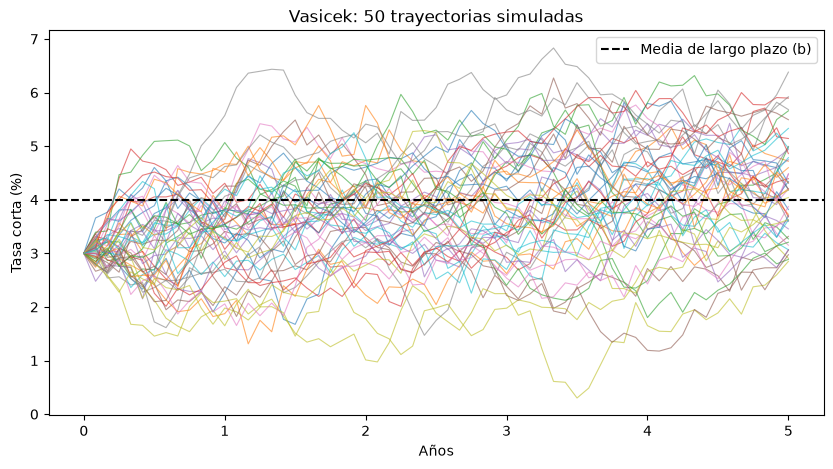

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(times, rates[:50].T * 100, lw=0.8, alpha=0.6)
ax.axhline(b * 100, color="black", ls="--", label="Media de largo plazo (b)")
ax.set_xlabel("Años")
ax.set_ylabel("Tasa corta (%)")
ax.set_title("Vasicek: 50 trayectorias simuladas")
ax.legend()
fig.savefig("../reports/figures/vasicek_paths.png", dpi=150, bbox_inches="tight")
plt.show()

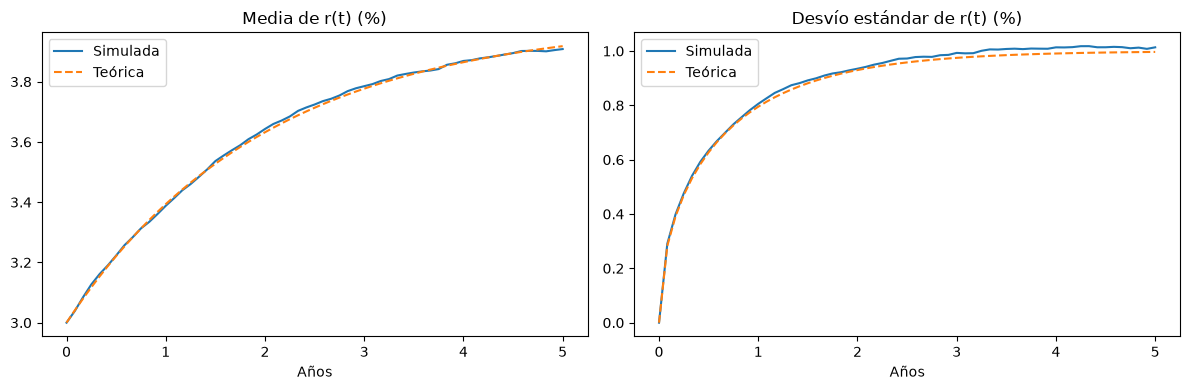

Media a 5 años   → simulada: 3.9083% | teórica: 3.9179%
Desvío a 5 años  → simulado: 1.0136% | teórico: 0.9966%


In [7]:
sim_mean = rates.mean(axis=0)
sim_var = rates.var(axis=0)

theo_mean = vasicek_mean(r0, a, b, times)
theo_var = vasicek_var(a, sigma, times)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(times, sim_mean * 100, label="Simulada")
axes[0].plot(times, theo_mean * 100, "--", label="Teórica")
axes[0].set_title("Media de r(t) (%)")
axes[0].set_xlabel("Años")
axes[0].legend()

axes[1].plot(times, np.sqrt(sim_var) * 100, label="Simulada")
axes[1].plot(times, np.sqrt(theo_var) * 100, "--", label="Teórica")
axes[1].set_title("Desvío estándar de r(t) (%)")
axes[1].set_xlabel("Años")
axes[1].legend()

plt.tight_layout()
fig.savefig("../reports/figures/vasicek_validation.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Media a 5 años   → simulada: {sim_mean[-1]:.4%} | teórica: {theo_mean[-1]:.4%}")
print(f"Desvío a 5 años  → simulado: {np.sqrt(sim_var[-1]):.4%} | teórico: {np.sqrt(theo_var[-1]):.4%}")